# Cre-loxP recombination with `connect`

Cre recombinase cuts two loxP sites in their 8 bp spacer and swaps the strands. What happens
to the DNA depends only on where the two sites are and which way they point:

| Sites | Direction | Outcome |
|-------|-----------|---------|
| one molecule | same direction (direct repeat) | the segment between them is excised as a circle |
| one molecule | opposite directions (inverted repeat) | the segment between them is inverted |
| two linear molecules | same direction | the arms beyond the sites are exchanged |
| a circle and a linear molecule | either | the circle integrates, in a direction that follows its site |

`SequenceGraph.connect(after=, before=)` adds one edge between two existing positions without
writing sequence, and a Cre event is two of them. This notebook builds each case and plots the result.
The last part puts the sites on separate molecules of one sample. A connection between two sequence
graphs folds them into one, so the products of a crossover between molecules live in a single graph,
as an excised circle does.

## Setup

A loxP site is a 13 bp arm, an 8 bp spacer and a 13 bp arm. The spacer is not palindromic, so a site
has a direction. Each linear molecule is imported as one sequence. An exact search finds each full
loxP site, and the bases on either side of the spacer midpoint give `connect` its cut positions.
`connect` splits the graph at those positions when they lie inside a node. Both sites carry the same
spacer, so the recombinant sites come out identical to the parental ones.

In [1]:
import tempfile

import gen

repository = gen.Repository(tempfile.mkdtemp(prefix="cre-lox-"))

LOXP = "ATAACTTCGTATA" + "ATGTATGC" + "TATACGAAGTTAT"
SITE_5, SITE_3 = LOXP[:17], LOXP[17:]

# The same site on the opposite strand reads as a site pointing the other way.
COMPLEMENT = str.maketrans("ACGT", "TGCA")
LOXP_REVERSED = LOXP.translate(COMPLEMENT)[::-1]
SITE_5_REVERSED, SITE_3_REVERSED = LOXP_REVERSED[:17], LOXP_REVERSED[17:]

# Flanks and segments between sites.
L, M, R = "GCTAGGCA", "CGTCTGAA", "TGGACCTT"

`find_cut_sites` searches the full site sequence and returns the positions on either side of
each cut. It can also annotate the original sites for display. `cre` takes those position pairs:
for sites pointing the same way, each left half is joined to the other site's right half. For
sites pointing opposite ways, the connections use reverse-complement positions to invert the
segment between them.

Cre is reversible, and a population always holds some molecules that have not reacted. So by
default each event stacks: the original continuity stays beside the new one. `stack=False`
retires it instead, for a molecule known to have reacted.

In [2]:
def find_cut_sites(sg, motif=LOXP, annotate=False):
    # Each linear molecule is one node, so node offsets order its sites.
    matches = sorted(sg.search(motif, sequence_kind="exact"), key=lambda match: match.start().offset)
    if annotate:
        for index, match in enumerate(matches):
            sg.add_annotation(match, f"LoxP{index}")
    return [(match[16], match[17]) for match in matches]


def cre(sg, first, second, same_direction, stack=True):
    first_left, first_right = first
    second_left, second_right = second
    if same_direction:
        # Close the loop before joining the flanks. Joining the flanks first leaves a one-node
        # segment with no live edge, and the second connection could no longer find its positions.
        sg.connect(after=second_left, before=first_right, stack=stack)
        sg.connect(after=first_left, before=second_right, stack=stack)
    else:
        sg.connect(after=first_left, before=second_left.reverse_complement(), stack=stack)
        sg.connect(after=first_right.reverse_complement(), before=second_right, stack=stack)

## Debugging helper

In [3]:
import networkx as nx
from matplotlib import pyplot as plt

def draw(sg):
    G = sg.to_networkx()
    weights = [G[u][v]["attr_dict"][0]["chromosome_index"] for u, v in G.edges()]
    
    pos = nx.planar_layout(G)
    
    nx.draw(G, pos,  edge_color=weights,  # Pass numerical values
        edge_cmap=plt.cm.Accent, with_labels=True)

## Two sites on one molecule

The first molecule has two direct-repeat sites, with `M` between them and `L` and `R` outside.
The site search returns the four bases that flank the two cuts:

In [4]:
sg = repository.import_sequence(L + LOXP + M + LOXP + R, name="molecule", sample="direct")
site_1, site_2 = find_cut_sites(sg, annotate=True)
sg.plot()

                          molecule




  ╟──g…a…t…a…t…t──╢
       [═] [═]



     |......|...
     0      60

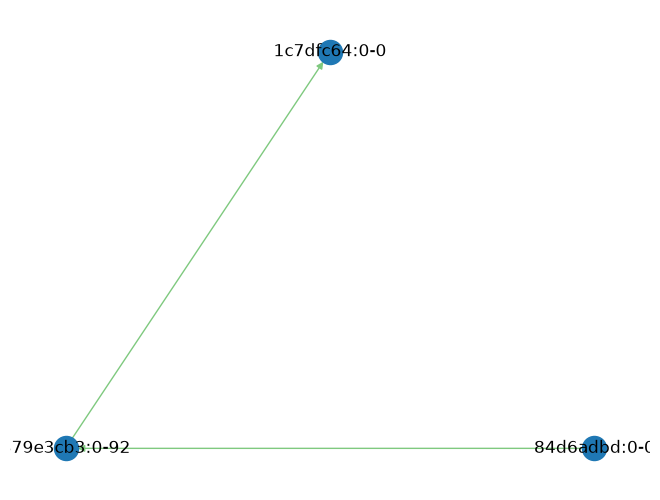

In [5]:
draw(sg)

Cre excises `M` with one site into a circle and leaves one site in the linear molecule. The unrecombined molecule stays beside its products:

In [6]:
cre(sg, site_1, site_2, same_direction=True)
sg.plot(interactive=True)

                          molecule


           ╭───────────╮
           │           │
  ╟──g…a…t─┴┬─a…t…a…t─┬┴─a…t…t──╢
       [══ ╭╯ ══] [══ ╰╮ ══]
           │           │
           ╰─────◀─────╯

     |............|...........
     0           50

With `stack=False` only the molecule that has reacted remains, the linear product and the circle. A circle is not reachable from the start of the molecule, so the plot needs `show_history=True` to keep it, and `align_path=False` to stop it laying everything out along one row. Retired edges are dashed:

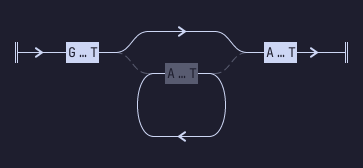

In [7]:
sg = repository.import_sequence(L + LOXP + M + LOXP + R, name="molecule", sample="direct_committed")
site_1, site_2 = find_cut_sites(sg)

cre(sg, site_1, site_2, same_direction=True, stack=False)
sg.plot(interactive=False, show_history=True, align_path=False)

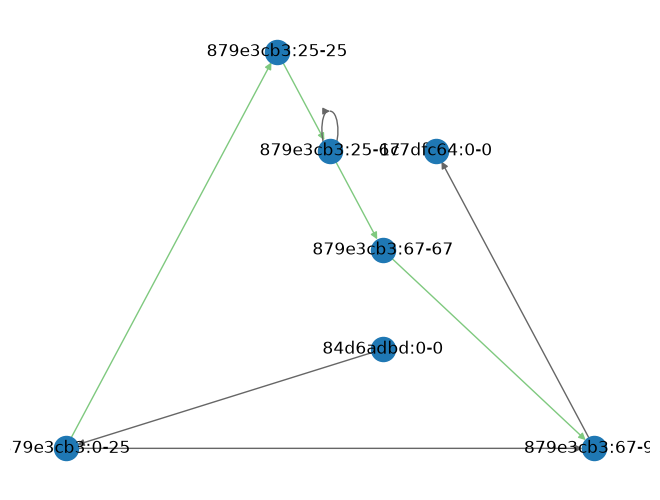

In [8]:
draw(sg)

The two `connect` calls are what `recombine` makes of two sites. `gen.Motif` holds the recognition site and the cut, `motif.apply` turns each search hit into a `Site`, and `recombine` exchanges the two sites as one operation. Without `split=True` it leaves the same single graph as `cre(..., stack=False)` above, with the circle and the retired edges:

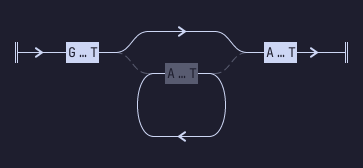

In [9]:
lox = gen.Motif(LOXP, 17, name="loxP")
sg = repository.import_sequence(L + LOXP + M + LOXP + R, name="molecule", sample="direct_recombine")
first, second = sorted(
    (lox.apply(hit) for hit in sg.search(lox.recognition_site, sequence_kind="exact")),
    key=lambda site: site.locus.start().offset,
)
sg.recombine(first, second)
sg.plot(interactive=False, show_history=True, align_path=False)

Sites pointing in opposite directions, an inverted repeat, invert the segment instead. Both sites are kept,
still inverted, and the reaction is reversible by the same two calls, which is why a population of such
molecules sits at a mix of both states:

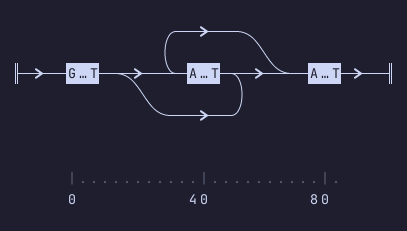

In [10]:
sg = repository.import_sequence(L + LOXP + M + LOXP_REVERSED + R, name="molecule", sample="inverted")
site_1 = find_cut_sites(sg, LOXP)[0]
site_2 = find_cut_sites(sg, LOXP_REVERSED)[0]

cre(sg, site_1, site_2, same_direction=False)
sg.plot(interactive=False)

## Three sites and two events

A molecule with three sites can lose its two segments one after the other. The second event acts on
the molecule the first one left behind. Positions name bases of the graph, not of one molecule:
after the first event, the linear molecule's left site has the left half of site 1 and the right
half of site 2. Its right site is site 3 as before.

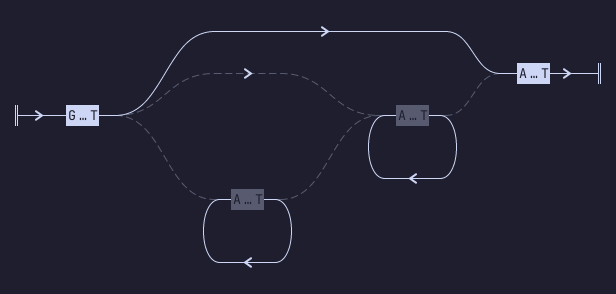

In [11]:
sg = repository.import_sequence(
    L + LOXP + "CGTCTGAA" + LOXP + "AGCTTGCA" + LOXP + R,
    name="molecule",
    sample="three_sites",
)
site_1, site_2, site_3 = find_cut_sites(sg)

# First event: sites 1 and 2 excise segment A.
cre(sg, site_1, site_2, same_direction=True, stack=False)
# Second event: the linear molecule carries the recombinant site 1/2 and site 3.
cre(sg, (site_1[0], site_2[1]), site_3, same_direction=True, stack=False)
sg.plot(interactive=False, show_history=True, align_path=False)

Both events completed, so the linear molecule has lost `A` and `B` and each segment is a
circle of its own. Using site 2's original left half for the second event would instead act on
the circle made by the first event.

With the default `stack=True` every event leaves the earlier molecules in place, which is the
population before either event is finished:

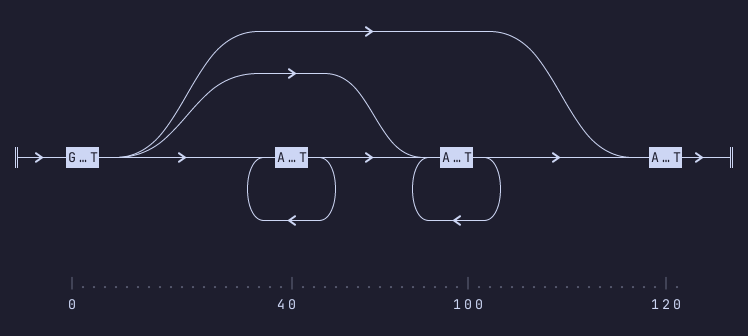

In [12]:
sg = repository.import_sequence(
    L + LOXP + "CGTCTGAA" + LOXP + "AGCTTGCA" + LOXP + R,
    name="molecule",
    sample="three_sites_stacked",
)
site_1, site_2, site_3 = find_cut_sites(sg)

cre(sg, site_1, site_2, same_direction=True)
cre(sg, (site_1[0], site_2[1]), site_3, same_direction=True)
sg.plot(interactive=False)

## Sites on several molecules

Now each molecule is its own sequence graph in one sample. Cre between sites on two molecules works the
same way, with the first site on one graph and the second on the other. When `connect` gets a position
from another graph of the sample, it folds that graph into the one it is called on. Both molecules are
then components of one graph, held together by the same marker edges as an excised circle, and the sample
is left with a single graph. The folded graph's paths move with it. Annotations of the folded graph
are copied onto it, and a name that is already taken takes a prime, so `P` moves as `P'`.

### Reciprocal exchange between linear molecules

before: ['chromosome_A', 'chromosome_B']


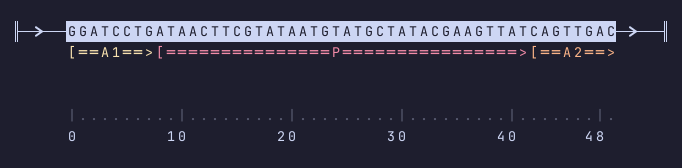

after: ['chromosome_A']


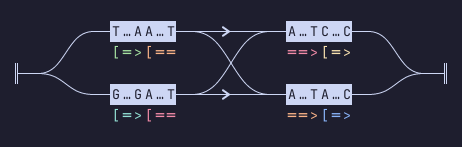

In [13]:
A1, A2, B1, B2 = "GGATCCTG", "CAGTTGAC", "TCCGATTA", "ACGGTACC"

a = repository.import_sequence(A1 + LOXP + A2, name="chromosome_A", sample="exchange")
a_site = find_cut_sites(a)[0]
b = repository.import_sequence(B1 + LOXP + B2, name="chromosome_B", sample="exchange")
b_site = find_cut_sites(b)[0]

for name, motif in zip(["A1", "A2", "B1","B2","P"],[A1, A2, B1, B2, LOXP]):
    for m in a.search(motif, sequence_kind="dna"):
        a.add_annotation(m, name)
    for m in b.search(motif, sequence_kind="dna"):
        b.add_annotation(m, name)
print("before:", [graph.name for graph in repository.sample("exchange")])
display(a.plot(interactive=False, detail="full"))
cre(a, a_site, b_site, same_direction=True)
print("after:", [graph.name for graph in repository.sample("exchange")])
a.plot(interactive=False, align_path=False)

The sample went from `chromosome_A` and `chromosome_B` to one graph, `chromosome_A`, holding both
recombinants beside the parental molecules, the picture of a cell population mid-reaction. With
`stack=False` the parental molecules are gone.

Two linear molecules whose sites point in opposite directions also exchange, but the products are one
ended: each carries a left arm and then runs backwards along the other molecule to its start. Gen reads
sequences from the start node of a graph to its end node, so these products are stored but not listed:

graphs: ['chromosome_A']
sequences read from start to end: 0


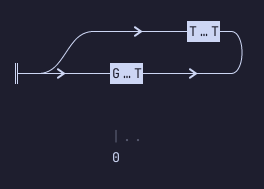

In [14]:
a = repository.import_sequence(A1 + LOXP + A2, name="chromosome_A", sample="exchange_opposed")
a_site = find_cut_sites(a)[0]
b = repository.import_sequence(B1 + LOXP_REVERSED + B2, name="chromosome_B", sample="exchange_opposed")
b_site = find_cut_sites(b, LOXP_REVERSED)[0]

cre(a, a_site, b_site, same_direction=False, stack=False)
print("graphs:", [graph.name for graph in repository.sample("exchange_opposed")])
print("sequences read from start to end:", len(a.all_sequences()))
a.plot(interactive=False)

### A circle joining a linear molecule

A circular plasmid with one site integrates into a linear molecule with one site. The plasmid's
site crosses its stored seam, so its cut is already a node boundary. The chromosome is imported
whole, and its site is found by the same exact search as above. The direction of the plasmid site
decides which way round it goes in.

`cre` joins two sites symmetrically, and a circle has one more constraint. The integrated molecule
has to be readable from the start of the chromosome to its end, so the second junction is joined
from the circle's side, whichever way the circle goes in. A plasmid whose site points the same
way as the chromosome's goes in as it is:

                          plasmid




                          ╭─A…T─╮
                          │     │
                          ╰──◀──╯


                            |..
                            0

                         chromosome




  ╟──ggatcctgataacttcgtataatgTAtgctatacgaagttatcagttgac──╢




     |...................|...................|.........
     0                  20                  40

graphs: ['chromosome']


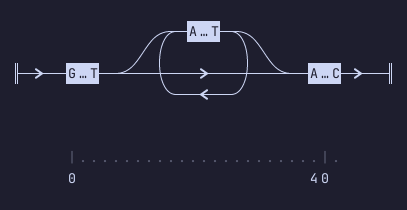

In [15]:
X = "GACGTCAG"

plasmid = repository.import_sequence(SITE_3 + X + SITE_5, name="plasmid", sample="integration", circular=True)
whole = plasmid.locus(0, len(SITE_3 + X + SITE_5))
# The plasmid's site is cut at its seam: the last base of the node and the first base.
plasmid_site = (whole.end(), whole.start())
display(plasmid.plot().zoom_in().show(plasmid_site[0],center=True))


chromosome = repository.import_sequence(A1 + LOXP + A2, name="chromosome", sample="integration")
chromosome_site = find_cut_sites(chromosome)[0]
display(chromosome.plot().zoom_in().zoom_in().show(chromosome_site[0]).show(chromosome_site[1],color='red',center=True))


chromosome.connect(after=plasmid_site[0], before=chromosome_site[1], stack=True)
chromosome.connect(after=chromosome_site[0], before=plasmid_site[1], stack=True)
print("graphs:", [graph.name for graph in repository.sample("integration")])
chromosome.plot(interactive=False)

A plasmid whose site points the other way goes in reversed: `X` is read as its reverse complement, and the two
sites flanking it still point the same way as each other. The second junction is joined through reverse-complement
positions:

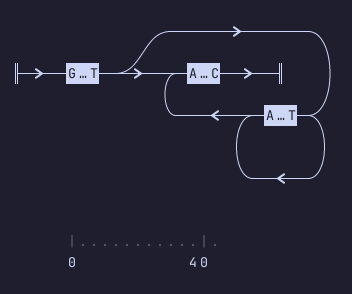

In [16]:
inverted_plasmid = repository.import_sequence(
    SITE_3_REVERSED + X + SITE_5_REVERSED, name="plasmid", sample="integration_inverted", circular=True
)
whole = inverted_plasmid.locus(0, len(SITE_3_REVERSED + X + SITE_5_REVERSED))
inverted_plasmid_site = (whole.end(), whole.start())

inverted_chromosome = repository.import_sequence(
    A1 + LOXP + A2, name="chromosome", sample="integration_inverted"
)
host_site = find_cut_sites(inverted_chromosome)[0]

inverted_chromosome.connect(
    after=host_site[0], before=inverted_plasmid_site[0].reverse_complement(), stack=True
)
inverted_chromosome.connect(
    after=inverted_plasmid_site[1].reverse_complement(), before=host_site[1], stack=True
)
inverted_chromosome.plot(interactive=False)

Integration leaves a direct repeat of sites around the plasmid, so it can leave again. The second Cre event acts on
the integrated molecule, between the site at the left junction and the site at the right junction:

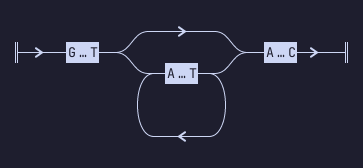

In [17]:
integrated_left, integrated_right = chromosome_site[0], plasmid_site[1]
integrated_end, integrated_after = plasmid_site[0], chromosome_site[1]
cre(chromosome, (integrated_left, integrated_right), (integrated_end, integrated_after), same_direction=True)
chromosome.plot(interactive=False, align_path=False)

The linear molecule and the plasmid are back, now as two components of the one graph rather
than two graphs. The integrated molecule is still there too, because the events stacked: some
molecules have not yet reacted.

## Notes on the model

* A Cre event is two `connect` calls, and the same two calls serve one molecule or two. Only the
  relative direction of the sites matters.
* Positions name bases of the graph, not of one molecule. When two events share a site, address
  the second one by the flanks of the molecule it acts on.
* `connect` can cut inside a node. It splits the graph at the cut and preserves or retires the
  original continuity according to `stack`.
* An inversion reads the segment between its cuts in reverse. The two internal cuts divide a
  whole imported molecule into the blocks needed for that route.
* Folding graphs keeps the start and end of each original graph as separate nodes of the folded
  graph, so each molecule has ends of its own and the molecules do not compete for one start node.
* Products that need the start of a second molecule read backwards, such as the opposed-site
  exchange above, are stored but not listed by `all_sequences()`.